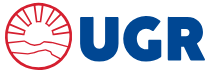



**Trabajo Final** - Ariel Fernandez  : *Clasificación del riesgo de derivación a Gestión Judicial en una cartera de préstamos personales mediante aprendizaje automático supervisado*



# Elección y aplicación del modelo para estimar el saldo en Gestión Judicial

Este notebook compara algoritmos de regresión y estima el saldo al momento de una eventual derivación a Gestión Judicial.

Su objetivo es estimar qué saldo podría conservar al momento de una eventual derivación cada préstamo previamente identificado con alerta de riesgo.

La comparación y el entrenamiento se realizan con los préstamos judiciales de **2024–2025** cuyo saldo quedó conservado en la situación observada al pase. Posteriormente, el algoritmo seleccionado se aplica a las alertas generadas para la cartera de 2026 y se valida con los saldos reales conocidos al **01/09/2026**.

## Variable objetivo

Se modela la proporción del total facturado que permanece como saldo al momento del pase:

`ratio_saldo_gj = saldo_congelado_al_pase / totalfac`

Luego se obtiene el saldo estimado:

`saldo_estimado_gj = ratio_estimado × totalfac`

## Algoritmos comparados

1. **Random Forest Regressor**.
2. **XGBoost Regressor**.

El criterio principal de selección es el menor **MAE en pesos**, calculado mediante validación cruzada agrupada por cliente dentro de Train. El conjunto de Test permanece reservado hasta finalizar la elección.



## Indice metodológico

1. Instalación e importación de las librerías.
2. Carga de la base de datos.
3. Identificación del saldo congelado y de la fecha de derivación a Gestión Judicial.
4. Construcción de la base histórica de operaciones judiciales de 2024–2025.
5. Definición de las variables predictoras.
6. Preprocesamiento de los datos y definición de las métricas.
7. División de Train y Test por cliente.
8. Definición de los algoritmos candidatos.
9. Comparación de configuraciones mediante validación cruzada dentro de Train.
   - 9.1. Comparación gráfica del MAE.
10. Selección del algoritmo.
11. Evaluación sobre el conjunto de Test.
    - 11.1. Gráficos de evaluación.
12. Entrenamiento y guardado de los modelos finales de saldo.
    - 12.1. Importancia relativa de las variables.
13. Integración con el modelo de clasificación.
14. Estimación del saldo de las operaciones con alerta.
15. Resultados conjuntos de clasificación y estimación del saldo.
16. Comparación con los saldos reales observados.
    - 16.1. Gráfico del saldo real frente al estimado en la cartera de 2026.
17. Exportación de las estimaciones y los resultados

## 1. Instalación e importaciones

In [ ]:

!pip -q install xgboost openpyxl joblib

import warnings, json
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, ParameterSampler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 200)

RANDOM_STATE = 42
TEST_SIZE = 0.25
N_SPLITS_CV = 3
FECHA_CORTE = pd.Timestamp("2026-09-01")


## 2. Carga de la base de datos

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

CARPETA = Path('/content/drive/MyDrive/PROYECTO TESIS/SEMINARIO')
RUTA_BASE = CARPETA / 'dataset2326v2.xlsx'

if not RUTA_BASE.exists():
    raise FileNotFoundError(f'No se encontró la base: {RUTA_BASE}')

df = pd.read_excel(RUTA_BASE)
df.columns = [str(c).strip() for c in df.columns]

print('Base general:', df.shape)
print('Años disponibles:',
      sorted(pd.to_numeric(df['añofac'], errors='coerce')
             .dropna().unique().tolist()))


Mounted at /content/drive
Base general: (48668, 40)
Años disponibles: [2023, 2024, 2025, 2026]



## 3. Identificación del saldo congelado y fecha de pase

buscar primero columna  `saldo`, porque esa es la variable histórica que se utilizará como saldo congelado al pase para los casos judiciales.
Para evitar tomar accidentalmente otra variable como `saldo vencido`, si no encuentra una coincidencia segura el código se detiene y muestra las columnas que contienen la palabra **saldo**.


In [ ]:

# ------------------------------------------------------------
# FECHA JUDICIAL
# ------------------------------------------------------------
COL_FECHA_JUDICIAL = None
for c in df.columns:
    if str(c).strip().upper() == 'FECHA JUDICIAL':
        COL_FECHA_JUDICIAL = c
        break

if COL_FECHA_JUDICIAL is None:
    raise KeyError("No se encontró la columna 'FECHA JUDICIAL'.")

# ------------------------------------------------------------
# SALDO CONGELADO
# ------------------------------------------------------------
mapa_cols = {str(c).strip().lower(): c for c in df.columns}

prioridad_saldo = [
    'saldo',
    'saldo factura',
    'saldo_factura',
    'saldofactura',
    'saldo al pase',
    'saldo al pase judicial',
    'saldo judicial',
    'saldo_gj_real'
]

COL_SALDO = None

for nombre in prioridad_saldo:
    if nombre.lower() in mapa_cols:
        COL_SALDO = mapa_cols[nombre.lower()]
        break

if COL_SALDO is None:
    candidatos = [c for c in df.columns if 'saldo' in str(c).lower()]
    print('Columnas que contienen SALDO:')
    for c in candidatos:
        print(' -', c)
    raise KeyError(
        "No pude identificar de forma segura la columna del saldo congelado. "
        "Revisá la lista anterior y reemplazá manualmente COL_SALDO por el nombre correcto."
    )

print('Fecha de pase identificada:', COL_FECHA_JUDICIAL)
print('Saldo congelado identificado:', COL_SALDO)

# Control visual de otras columnas con saldo
print('\nOtras columnas que contienen "saldo":')
for c in df.columns:
    if 'saldo' in str(c).lower():
        print(' -', c)


Fecha de pase identificada: FECHA JUDICIAL
Saldo congelado identificado: saldofactura

Otras columnas que contienen "saldo":
 - saldofactura
 - saldo_relativo


## 4. Construcción de la base de saldo 2024–2025

In [ ]:

d = df.copy()

d['añofac'] = pd.to_numeric(d['añofac'], errors='coerce')
d['target_num'] = pd.to_numeric(d['target'], errors='coerce')
d['fecha_judicial_real'] = pd.to_datetime(
    d[COL_FECHA_JUDICIAL],
    errors='coerce',
    dayfirst=True
)
d['saldo_gj_real'] = pd.to_numeric(
    d[COL_SALDO],
    errors='coerce'
)
d['totalfac'] = pd.to_numeric(
    d['totalfac'],
    errors='coerce'
)

# Sólo operaciones que efectivamente terminaron en judicial.
# V2: target 2 y 5 = Judicial.
base = d[
    d['añofac'].isin([2024, 2025]) &
    d['target_num'].isin([2, 5]) &
    d['fecha_judicial_real'].notna() &
    d['saldo_gj_real'].notna() &
    d['totalfac'].gt(0)
].copy()

# Tipo de población
tipo = base['tipocredito'].astype(str).str.upper().str.strip()

base['poblacion'] = np.select(
    [
        tipo.str.contains('APERTURA', na=False),
        tipo.str.contains('RENOV', na=False)
    ],
    ['Apertura', 'Renovación'],
    default='Otra'
)

base = base[
    base['poblacion'].isin(['Apertura', 'Renovación'])
].copy()

# Ratio antes de recortar: control metodológico
base['ratio_saldo_sin_clip'] = (
    base['saldo_gj_real'] / base['totalfac']
)

print('Casos judiciales 2024-2025 con saldo disponible:', len(base))
print('Saldo negativo:', int((base['saldo_gj_real'] < 0).sum()))
print('Ratio < 0:', int((base['ratio_saldo_sin_clip'] < 0).sum()))
print('Ratio > 1:', int((base['ratio_saldo_sin_clip'] > 1).sum()))

# El objetivo queda acotado entre 0 y 1.
base['ratio_saldo_gj'] = base['ratio_saldo_sin_clip'].clip(0, 1)

# Feature ya utilizada en V2
base['relacion_cuota_ingreso'] = np.where(
    pd.to_numeric(base['SUELDO'], errors='coerce') > 0,
    pd.to_numeric(base['monto_cuota'], errors='coerce') /
    pd.to_numeric(base['SUELDO'], errors='coerce') * 100,
    np.nan
)

resumen_base = (
    base.groupby(['poblacion', 'añofac'])
    .agg(
        Casos=('id_cliente', 'size'),
        Clientes=('id_cliente', 'nunique'),
        Saldo_real=('saldo_gj_real', 'sum'),
        Total_facturado=('totalfac', 'sum'),
        Ratio_medio=('ratio_saldo_gj', 'mean'),
        Ratio_mediano=('ratio_saldo_gj', 'median')
    )
    .reset_index()
)

display(
    resumen_base.style.format({
        'Saldo_real': '${:,.0f}',
        'Total_facturado': '${:,.0f}',
        'Ratio_medio': '{:.2%}',
        'Ratio_mediano': '{:.2%}'
    })
)


Casos judiciales 2024-2025 con saldo disponible: 9745
Saldo negativo: 0
Ratio < 0: 0
Ratio > 1: 0


,poblacion,añofac,Casos,Clientes,Saldo_real,Total_facturado,Ratio_medio,Ratio_mediano
0,Apertura,2024,3050,3050,"$4,031,542,578","$4,875,999,511",82.18%,92.34%
1,Apertura,2025,2966,2966,"$7,985,242,288","$8,994,887,360",87.02%,93.45%
2,Renovación,2024,1751,1506,"$2,130,360,707","$3,115,529,845",67.33%,70.37%
3,Renovación,2025,1978,1766,"$5,381,393,720","$6,406,020,176",81.09%,87.23%



## 5. Variables predictoras

Se utilizan solamente variables disponibles al otorgamiento o, en Renovación, antecedentes previos del cliente.

**No se utilizan como predictores:**
- saldo congelado al pase,
- fecha judicial,
- días de mora posteriores,
- variables que describan el desenlace futuro.

Se utilizan las mismas **14 variables de Apertura y 20 de Renovación** que en clasificación. Ambas poblaciones incluyen sueldo, monto de cuota y relación cuota-ingreso; Renovación incorpora además seis variables de historial previo.


In [ ]:

NUM_AP = [
    'capitalprestado',
    'plan',
    'interes',
    'totalfac',
    'costo_credito',
    'monto_cuota',
    'SUELDO',
    'relacion_cuota_ingreso'
]

CAT_AP = [
    'rscore',
    'actividad',
    'rangoedad',
    'genero',
    'provincia',
    'sucursal'
]

NUM_RE = [
    'SUELDO',
    'monto_cuota',
    'capitalprestado',
    'plan',
    'interes',
    'totalfac',
    'costo_credito',
    'relacion_cuota_ingreso',
    'antiguedad_credito',
    'cantidad_prestamos_anteriores',
    'tuvo_mora_anterior',
    'max_mora_prestamos_anteriores',
    'prestamos_cancelados_normal',
    'prestamos_en_judicial_anteriores'
]

CAT_RE = [
    'rscore',
    'actividad',
    'rangoedad',
    'genero',
    'provincia',
    'sucursal'
]

CONFIG_POB = {
    'Apertura': {'num': NUM_AP, 'cat': CAT_AP},
    'Renovación': {'num': NUM_RE, 'cat': CAT_RE}
}

for pob, cfg in CONFIG_POB.items():
    faltan = [
        c for c in cfg['num'] + cfg['cat']
        if c not in base.columns
    ]
    print(pob, '-> variables:', len(cfg['num'] + cfg['cat']))
    print('Faltantes:', faltan)
    if faltan:
        raise KeyError(f'{pob}: faltan variables {faltan}')


Apertura -> variables: 14
Faltantes: []
Renovación -> variables: 20
Faltantes: []


## 6. Preprocesamiento y métricas

In [ ]:

def preprocesador(num, cat):
    try:
        ohe = OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=True
        )
    except TypeError:
        ohe = OneHotEncoder(
            handle_unknown='ignore',
            sparse=True
        )

    return ColumnTransformer([
        (
            'num',
            Pipeline([
                ('imputar', SimpleImputer(strategy='median')),
                ('escalar', StandardScaler())
            ]),
            num
        ),
        (
            'cat',
            Pipeline([
                ('imputar', SimpleImputer(strategy='most_frequent')),
                ('onehot', ohe)
            ]),
            cat
        )
    ])


def saldo_desde_ratio(ratio, totalfac):
    ratio = np.clip(np.asarray(ratio, dtype=float), 0, 1)
    totalfac = np.asarray(totalfac, dtype=float)
    return ratio * totalfac


def metricas_saldo(real, pred):
    real = np.asarray(real, dtype=float)
    pred = np.asarray(pred, dtype=float)
    error = pred - real

    return {
        'Casos': len(real),
        'MAE_$': mean_absolute_error(real, pred),
        'RMSE_$': mean_squared_error(real, pred) ** 0.5,
        'R2_$': r2_score(real, pred) if len(real) > 1 else np.nan,
        'Sesgo_$': error.mean(),
        'Mediana_abs_error_$': np.median(np.abs(error)),
        'Saldo_real_$': real.sum(),
        'Saldo_estimado_$': pred.sum(),
        'Diferencia_$': pred.sum() - real.sum(),
        'Error_agregado_%':
            ((pred.sum() / real.sum()) - 1) * 100
            if real.sum() != 0 else np.nan
    }


## 7. Train/Test agrupado por cliente

In [ ]:

POBLACIONES = {}

for pob in ['Apertura', 'Renovación']:
    sub = base[
        base['poblacion'].eq(pob)
    ].copy().reset_index(drop=True)

    if sub['id_cliente'].isna().any():
        raise ValueError(f'{pob}: existen id_cliente nulos.')

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE
    )

    idx_train, idx_test = next(
        splitter.split(
            sub,
            groups=sub['id_cliente']
        )
    )

    train = sub.iloc[idx_train].reset_index(drop=True)
    test = sub.iloc[idx_test].reset_index(drop=True)

    POBLACIONES[pob] = {
        'train': train,
        'test': test,
        **CONFIG_POB[pob]
    }

    comunes = set(train['id_cliente']).intersection(
        set(test['id_cliente'])
    )

    print('\n', pob)
    print('Train:', len(train), '| Test:', len(test))
    print('Clientes compartidos Train/Test:', len(comunes))



 Apertura
Train: 4512 | Test: 1504
Clientes compartidos Train/Test: 0

 Renovación
Train: 2791 | Test: 938
Clientes compartidos Train/Test: 0


## 8. Dos algoritmos candidatos

Se comparan **Random Forest Regressor** y **XGBoost Regressor**, con las mismas particiones agrupadas por cliente.

La elección se realiza únicamente dentro de Train, utilizando como criterio principal el menor MAE en pesos. Se mantienen las configuraciones y la cantidad de combinaciones previstas para cada algoritmo.


In [ ]:

RF_CONFIGS = [
    {
        'n_estimators': 400,
        'max_depth': None,
        'min_samples_leaf': 3,
        'max_features': 1.0
    },
    {
        'n_estimators': 500,
        'max_depth': None,
        'min_samples_leaf': 5,
        'max_features': 1.0
    },
    {
        'n_estimators': 500,
        'max_depth': 12,
        'min_samples_leaf': 3,
        'max_features': 0.8
    },
    {
        'n_estimators': 700,
        'max_depth': 14,
        'min_samples_leaf': 5,
        'max_features': 0.8
    }
]

XGB_SPACE = {
    'n_estimators': [300, 500, 700, 900],
    'max_depth': [2, 3, 4],
    'learning_rate': [0.025, 0.04, 0.06, 0.08],
    'min_child_weight': [1, 3, 5, 8, 12],
    'subsample': [0.70, 0.80, 0.90, 1.0],
    'colsample_bytree': [0.70, 0.80, 0.90, 1.0],
    'reg_lambda': [1, 3, 5, 10, 20],
    'reg_alpha': [0, 0.05, 0.2, 0.5, 1.0],
    'gamma': [0, 0.05, 0.2]
}

XGB_CONFIGS = list(
    ParameterSampler(
        XGB_SPACE,
        n_iter=12,
        random_state=RANDOM_STATE
    )
)

CONFIGS = {
    'Random Forest': RF_CONFIGS,
    'XGBoost Regressor': XGB_CONFIGS
}


In [ ]:

def crear_pipeline(nombre, params, num, cat):
    pre = preprocesador(num, cat)

    if nombre == 'Random Forest':
        modelo = RandomForestRegressor(
            **params,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )

    elif nombre == 'XGBoost Regressor':
        modelo = XGBRegressor(
            **params,
            objective='reg:squarederror',
            random_state=RANDOM_STATE,
            n_jobs=-1,
            tree_method='hist'
        )

    else:
        raise ValueError(nombre)

    return Pipeline([
        ('pre', pre),
        ('modelo', modelo)
    ])


## 9. Comparación de configuraciones dentro de Train

In [ ]:

resultados_cv = []
mejores_params = {}

for pob in ['Apertura', 'Renovación']:
    info = POBLACIONES[pob]
    train = info['train']
    num = info['num']
    cat = info['cat']
    variables = num + cat

    cv = GroupKFold(n_splits=N_SPLITS_CV)

    for nombre, lista_params in CONFIGS.items():
        mejor = None

        for params in lista_params:
            maes = []
            rmses = []
            errores_agregados = []

            for idx_tr, idx_va in cv.split(
                train,
                groups=train['id_cliente']
            ):
                tr = train.iloc[idx_tr]
                va = train.iloc[idx_va]

                pipe = crear_pipeline(
                    nombre,
                    params,
                    num,
                    cat
                )

                pipe.fit(
                    tr[variables],
                    tr['ratio_saldo_gj']
                )

                ratio_pred = np.clip(
                    pipe.predict(va[variables]),
                    0, 1
                )

                saldo_pred = saldo_desde_ratio(
                    ratio_pred,
                    va['totalfac']
                )

                saldo_real = va['saldo_gj_real'].to_numpy()

                maes.append(
                    mean_absolute_error(
                        saldo_real,
                        saldo_pred
                    )
                )

                rmses.append(
                    mean_squared_error(
                        saldo_real,
                        saldo_pred
                    ) ** 0.5
                )

                errores_agregados.append(
                    abs(
                        (saldo_pred.sum() /
                         saldo_real.sum() - 1) * 100
                    )
                )

            fila = {
                'Población': pob,
                'Modelo': nombre,
                'Parámetros': json.dumps(
                    params,
                    ensure_ascii=False
                ),
                'CV_MAE_$': np.mean(maes),
                'CV_RMSE_$': np.mean(rmses),
                'CV_Error_agregado_abs_%':
                    np.mean(errores_agregados)
            }

            resultados_cv.append(fila)

            clave = (
                fila['CV_MAE_$'],
                fila['CV_Error_agregado_abs_%'],
                fila['CV_RMSE_$']
            )

            if mejor is None or clave < mejor[0]:
                mejor = (
                    clave,
                    params.copy(),
                    fila.copy()
                )

        mejores_params[(pob, nombre)] = mejor[1]

tabla_cv = pd.DataFrame(resultados_cv)

tabla_mejor_cv = (
    tabla_cv
    .sort_values([
        'Población',
        'Modelo',
        'CV_MAE_$',
        'CV_Error_agregado_abs_%',
        'CV_RMSE_$'
    ])
    .groupby(
        ['Población', 'Modelo'],
        as_index=False
    )
    .first()
    .sort_values([
        'Población',
        'CV_MAE_$'
    ])
)

display(
    tabla_mejor_cv.style.format({
        'CV_MAE_$': '${:,.0f}',
        'CV_RMSE_$': '${:,.0f}',
        'CV_Error_agregado_abs_%': '{:.3f}%'
    })
)


,Población,Modelo,Parámetros,CV_MAE_$,CV_RMSE_$,CV_Error_agregado_abs_%
0,Apertura,Random Forest,"{""n_estimators"": 400, ""max_depth"": null, ""min_samples_leaf"": 3, ""max_features"": 1.0}","$221,066","$322,861",0.306%
1,Apertura,XGBoost Regressor,"{""subsample"": 0.9, ""reg_lambda"": 20, ""reg_alpha"": 1.0, ""n_estimators"": 700, ""min_child_weight"": 8, ""max_depth"": 3, ""learning_rate"": 0.06, ""gamma"": 0, ""colsample_bytree"": 0.8}","$232,727","$333,416",0.264%
3,Renovación,XGBoost Regressor,"{""subsample"": 0.9, ""reg_lambda"": 20, ""reg_alpha"": 1.0, ""n_estimators"": 700, ""min_child_weight"": 8, ""max_depth"": 3, ""learning_rate"": 0.06, ""gamma"": 0, ""colsample_bytree"": 0.8}","$270,266","$386,138",0.770%
2,Renovación,Random Forest,"{""n_estimators"": 400, ""max_depth"": null, ""min_samples_leaf"": 3, ""max_features"": 1.0}","$274,833","$385,796",0.987%


### 9.1. Comparación gráfica del MAE en validación cruzada

Se muestran las mejores configuraciones de los dos algoritmos, por separado para cada población. Un MAE menor indica un error promedio menor en pesos.


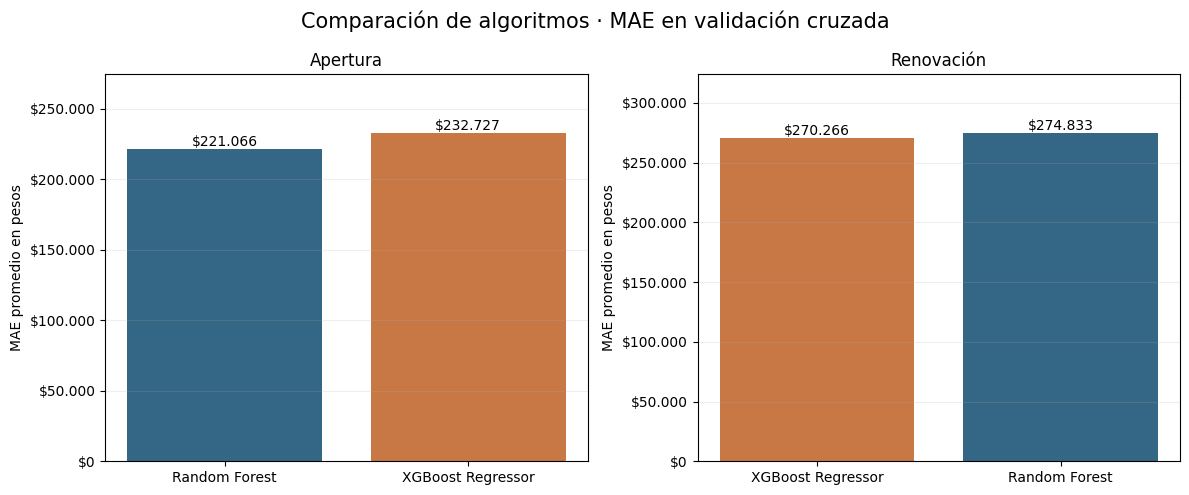

In [ ]:
# Comparación gráfica de errores en validación cruzada: menor es mejor.
def formato_pesos_eje(valor, posicion=None):
    return '$' + f'{valor:,.0f}'.replace(',', '.')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colores_modelos = {'Random Forest': '#346785', 'XGBoost Regressor': '#C87845'}
for ax, pob in zip(axes, ['Apertura', 'Renovación']):
    datos_grafico = tabla_mejor_cv.loc[tabla_mejor_cv['Población'].eq(pob)].sort_values('CV_MAE_$')
    barras = ax.bar(datos_grafico['Modelo'], datos_grafico['CV_MAE_$'],
                    color=[colores_modelos[m] for m in datos_grafico['Modelo']])
    for barra, valor in zip(barras, datos_grafico['CV_MAE_$']):
        ax.text(barra.get_x() + barra.get_width()/2, valor,
                formato_pesos_eje(valor), ha='center', va='bottom', fontsize=10)
    ax.set_title(pob)
    ax.set_ylabel('MAE promedio en pesos')
    ax.yaxis.set_major_formatter(FuncFormatter(formato_pesos_eje))
    ax.set_ylim(0, max(datos_grafico['CV_MAE_$'].max() * 1.18, 1))
    ax.grid(axis='y', alpha=0.2)
fig.suptitle('Comparación de algoritmos · MAE en validación cruzada', fontsize=15)
fig.tight_layout()
fig.savefig(CARPETA / '04_COMPARACION_MAE_CV.png', dpi=220, bbox_inches='tight')
plt.show()


## 10. Selección del algoritmo

Se muestra el ganador por población y un ranking global basado en el promedio del rango obtenido por MAE CV en Apertura y Renovación. En caso de empate en el ranking, se utiliza el MAE CV promedio.

El algoritmo final se determina con esta comparación dentro de Train; no se fija de antemano a Random Forest ni a XGBoost y no se utilizan los resultados de 2026 para seleccionarlo.


In [ ]:

# Ranking dentro de cada población
ranking = tabla_mejor_cv.copy()

ranking['Ranking_MAE'] = (
    ranking.groupby('Población')['CV_MAE_$']
    .rank(method='min')
)

ranking_global = (
    ranking.groupby('Modelo')
    .agg(
        Ranking_promedio=('Ranking_MAE', 'mean'),
        MAE_CV_promedio=('CV_MAE_$', 'mean'),
        RMSE_CV_promedio=('CV_RMSE_$', 'mean')
    )
    .reset_index()
    .sort_values([
        'Ranking_promedio',
        'MAE_CV_promedio'
    ])
)

print('GANADOR POR POBLACIÓN')
for pob in ['Apertura', 'Renovación']:
    fila = (
        tabla_mejor_cv[
            tabla_mejor_cv['Población'].eq(pob)
        ]
        .sort_values('CV_MAE_$')
        .iloc[0]
    )
    print(
        f"{pob}: {fila['Modelo']} | "
        f"MAE CV = ${fila['CV_MAE_$']:,.0f}"
    )

print('\nRANKING GLOBAL')
display(
    ranking_global.style.format({
        'Ranking_promedio': '{:.2f}',
        'MAE_CV_promedio': '${:,.0f}',
        'RMSE_CV_promedio': '${:,.0f}'
    })
)

MODELO_GLOBAL_GANADOR = ranking_global.iloc[0]['Modelo']

print('\nModelo global mejor posicionado:', MODELO_GLOBAL_GANADOR)


GANADOR POR POBLACIÓN
Apertura: Random Forest | MAE CV = $221,066
Renovación: XGBoost Regressor | MAE CV = $270,266

RANKING GLOBAL


,Modelo,Ranking_promedio,MAE_CV_promedio,RMSE_CV_promedio
0,Random Forest,1.50,"$247,950","$354,328"
1,XGBoost Regressor,1.50,"$251,497","$359,777"



Modelo global mejor posicionado: Random Forest



## 11. Test reservado

Se evalúan los dos algoritmos en Test utilizando exclusivamente la mejor configuración que cada uno obtuvo dentro de Train.

El Test **no modifica** los hiperparámetros.


In [ ]:

filas_test = []
detalle_test = []

for pob in ['Apertura', 'Renovación']:
    info = POBLACIONES[pob]

    train = info['train']
    test = info['test']
    num = info['num']
    cat = info['cat']
    variables = num + cat

    for nombre in [
        'Random Forest',
        'XGBoost Regressor'
    ]:
        params = mejores_params[(pob, nombre)]

        pipe = crear_pipeline(
            nombre,
            params,
            num,
            cat
        )

        pipe.fit(
            train[variables],
            train['ratio_saldo_gj']
        )

        ratio_pred = np.clip(
            pipe.predict(test[variables]),
            0, 1
        )

        saldo_pred = saldo_desde_ratio(
            ratio_pred,
            test['totalfac']
        )

        met = metricas_saldo(
            test['saldo_gj_real'],
            saldo_pred
        )

        filas_test.append({
            'Población': pob,
            'Modelo': nombre,
            **met
        })

        tmp = test[
            [
                'id_cliente',
                'añofac',
                'tipocredito',
                'totalfac',
                'saldo_gj_real',
                'fecha_judicial_real'
            ]
        ].copy()

        # Agregar factura/operación si existe
        for posible in ['operacion', 'factura']:
            if posible in test.columns:
                tmp[posible] = test[posible].values

        tmp['Población'] = pob
        tmp['Modelo'] = nombre
        tmp['ratio_estimado'] = ratio_pred
        tmp['saldo_estimado_gj'] = saldo_pred
        tmp['error_$'] = (
            tmp['saldo_estimado_gj'] -
            tmp['saldo_gj_real']
        )

        detalle_test.append(tmp)

tabla_test = pd.DataFrame(filas_test).sort_values([
    'Población',
    'MAE_$'
])

detalle_test = pd.concat(
    detalle_test,
    ignore_index=True
)

display(
    tabla_test.style.format({
        'MAE_$': '${:,.0f}',
        'RMSE_$': '${:,.0f}',
        'R2_$': '{:.4f}',
        'Sesgo_$': '${:,.0f}',
        'Mediana_abs_error_$': '${:,.0f}',
        'Saldo_real_$': '${:,.0f}',
        'Saldo_estimado_$': '${:,.0f}',
        'Diferencia_$': '${:,.0f}',
        'Error_agregado_%': '{:.3f}%'
    })
)


,Población,Modelo,Casos,MAE_$,RMSE_$,R2_$,Sesgo_$,Mediana_abs_error_$,Saldo_real_$,Saldo_estimado_$,Diferencia_$,Error_agregado_%
0,Apertura,Random Forest,1504,"$212,995","$318,998",0.9682,"$-5,299","$135,574","$3,090,909,057","$3,082,939,851","$-7,969,206",-0.258%
1,Apertura,XGBoost Regressor,1504,"$224,444","$323,947",0.9672,"$-4,745","$152,231","$3,090,909,057","$3,083,772,945","$-7,136,113",-0.231%
3,Renovación,XGBoost Regressor,938,"$264,382","$387,557",0.9543,"$-7,834","$178,074","$1,851,653,830","$1,844,305,105","$-7,348,725",-0.397%
2,Renovación,Random Forest,938,"$264,706","$382,059",0.9556,"$-10,077","$177,869","$1,851,653,830","$1,842,201,692","$-9,452,139",-0.510%


### 11.1. Gráficos de evaluación en Test

Se muestran MAE y RMSE de ambos algoritmos. El gráfico de saldo real frente al estimado utiliza las predicciones en Test del algoritmo seleccionado en validación cruzada; los puntos cercanos a la diagonal representan estimaciones más próximas al saldo real.


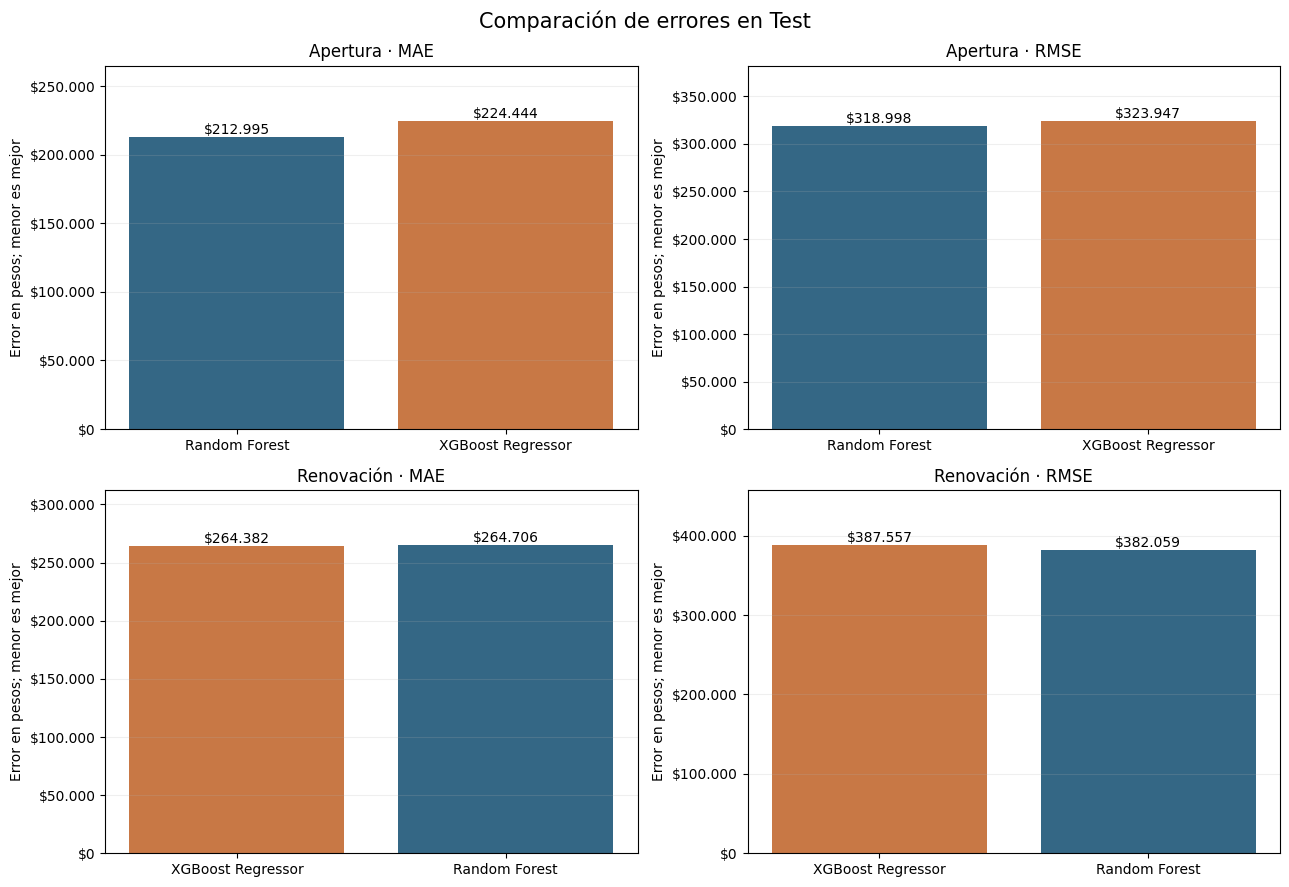

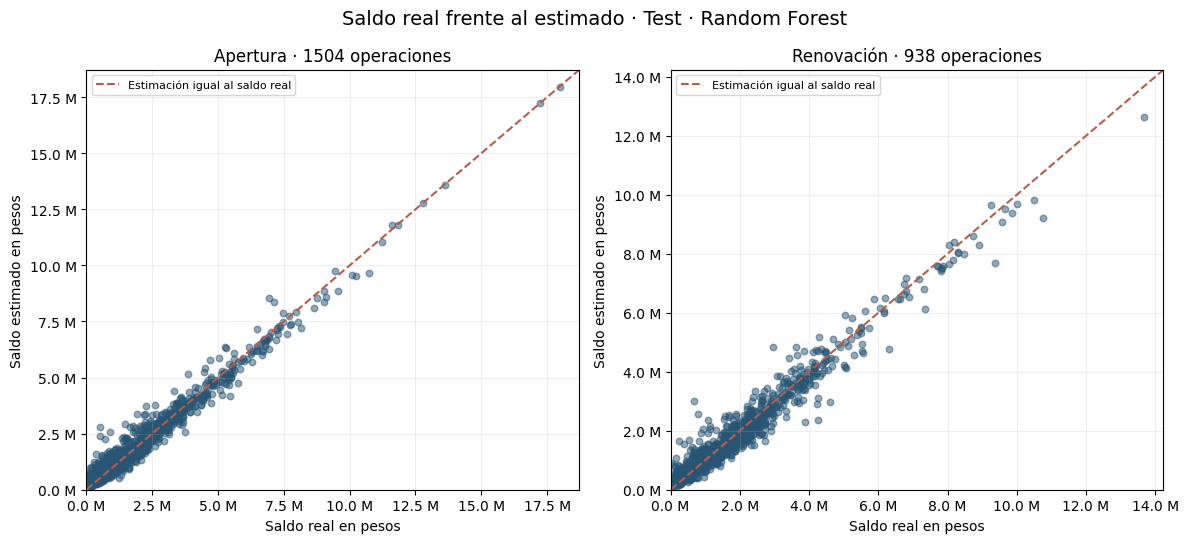

In [ ]:
# Comparar las métricas en Test sin utilizarlas para volver a ajustar los modelos.
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for fila, pob in enumerate(['Apertura', 'Renovación']):
    datos_grafico = tabla_test.loc[tabla_test['Población'].eq(pob)]
    for columna, metrica in enumerate(['MAE_$', 'RMSE_$']):
        ax = axes[fila, columna]
        barras = ax.bar(datos_grafico['Modelo'], datos_grafico[metrica],
                        color=[colores_modelos[m] for m in datos_grafico['Modelo']])
        for barra, valor in zip(barras, datos_grafico[metrica]):
            ax.text(barra.get_x()+barra.get_width()/2, valor,
                    formato_pesos_eje(valor), ha='center', va='bottom', fontsize=10)
        ax.set_title(pob + ' · ' + metrica.replace('_$', ''))
        ax.set_ylim(0, max(datos_grafico[metrica].max()*1.18, 1))
        ax.yaxis.set_major_formatter(FuncFormatter(formato_pesos_eje))
        ax.set_ylabel('Error en pesos; menor es mejor')
        ax.grid(axis='y', alpha=0.2)
fig.suptitle('Comparación de errores en Test', fontsize=15)
fig.tight_layout()
fig.savefig(CARPETA / '04_ERRORES_TEST.png', dpi=220, bbox_inches='tight')
plt.show()


def graficar_real_estimado_saldo(datos, columna_real, columna_estimada, columna_poblacion, titulo, ruta):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
    for ax, pob in zip(axes, ['Apertura', 'Renovación']):
        datos_pob = datos.loc[datos[columna_poblacion].eq(pob)]
        real = pd.to_numeric(datos_pob[columna_real], errors='coerce')
        estimado = pd.to_numeric(datos_pob[columna_estimada], errors='coerce')
        validos = np.isfinite(real) & np.isfinite(estimado)
        real, estimado = real[validos], estimado[validos]
        if len(real):
            ax.scatter(real, estimado, alpha=0.5, s=22, color='#285574')
            limite = max(real.max(), estimado.max(), 1) * 1.04
            ax.plot([0, limite], [0, limite], '--', color='#B65D4A', label='Estimación igual al saldo real')
            ax.set_xlim(0, limite); ax.set_ylim(0, limite)
            ax.legend(fontsize=8, loc='upper left')
        else:
            ax.text(0.5, 0.5, 'Sin casos evaluables', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(f'{pob} · {len(real)} operaciones')
        ax.set_xlabel('Saldo real en pesos'); ax.set_ylabel('Saldo estimado en pesos')
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x/1e6:.1f} M'))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f'{y/1e6:.1f} M'))
        ax.grid(alpha=0.2)
    fig.suptitle(titulo, fontsize=14)
    fig.tight_layout()
    fig.savefig(ruta, dpi=220, bbox_inches='tight')
    plt.show()

# Son las predicciones del modelo entrenado SOLO con Train, evaluadas en Test.
# No se utiliza aquí el modelo reentrenado con la base completa.
detalle_test_modelo_elegido = detalle_test.loc[detalle_test['Modelo'].eq(MODELO_GLOBAL_GANADOR)].copy()
graficar_real_estimado_saldo(
    detalle_test_modelo_elegido, 'saldo_gj_real', 'saldo_estimado_gj', 'Población',
    'Saldo real frente al estimado · Test · ' + str(MODELO_GLOBAL_GANADOR),
    CARPETA / '04_REAL_VS_ESTIMADO_TEST.png'
)


## 12. Modelo final de saldo

Para mantener un único algoritmo en Apertura y Renovación, se utiliza el mejor posicionado en el ranking global de validación cruzada dentro de Train.

Luego se reentrena con todos los préstamos judiciales de 2024–2025 incluidos en la base histórica y se guardan los modelos por población.


In [ ]:

MODELO_FINAL = MODELO_GLOBAL_GANADOR

print('MODELO FINAL SELECCIONADO:', MODELO_FINAL)

modelos_finales = {}

for pob in ['Apertura', 'Renovación']:
    num = CONFIG_POB[pob]['num']
    cat = CONFIG_POB[pob]['cat']
    variables = num + cat

    sub = base[
        base['poblacion'].eq(pob)
    ].copy()

    params = mejores_params[
        (pob, MODELO_FINAL)
    ]

    pipe = crear_pipeline(
        MODELO_FINAL,
        params,
        num,
        cat
    )

    pipe.fit(
        sub[variables],
        sub['ratio_saldo_gj']
    )

    modelos_finales[pob] = pipe

    nombre_archivo = (
        'MODELO_SALDO_FINAL_'
        + pob.upper().replace('Ó', 'O')
        + '.joblib'
    )

    ruta_modelo = CARPETA / nombre_archivo
    joblib.dump(pipe, ruta_modelo)

    print(
        pob,
        '| casos:',
        len(sub),
        '| guardado:',
        ruta_modelo
    )


MODELO FINAL SELECCIONADO: Random Forest
Apertura | casos: 6016 | guardado: /content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/MODELO_SALDO_FINAL_APERTURA.joblib
Renovación | casos: 3729 | guardado: /content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/MODELO_SALDO_FINAL_RENOVACION.joblib


### 12.1. Importancia relativa de las variables del modelo de saldo

Las importancias se obtienen de los árboles del modelo final y se agrupan según la variable original después de One-Hot Encoding. Se normalizan por población; describen el uso de las variables y no relaciones de causa y efecto. Las barras rosadas corresponden al historial crediticio.


IMPORTANCIA DE VARIABLES · Apertura · Random Forest


Variable mostrada,Importancia relativa (%)
Costo del crédito,23.92%
Relación cuota-ingreso,11.82%
Total facturado,11.23%
Sueldo,9.93%
Monto de cuota,8.97%
Plan de cuotas,8.28%
Score,5.39%
Interés,4.53%
Rango de edad,3.93%
Sucursal,3.56%


IMPORTANCIA DE VARIABLES · Renovación · Random Forest


Variable mostrada,Importancia relativa (%)
Antigüedad crediticia,26.23%
Costo del crédito,13.56%
Plan de cuotas,13.13%
Sueldo,5.86%
Relación cuota-ingreso,5.65%
Judiciales anteriores,5.54%
Máxima mora anterior,4.20%
Total facturado,3.55%
Monto de cuota,3.19%
Interés,3.14%


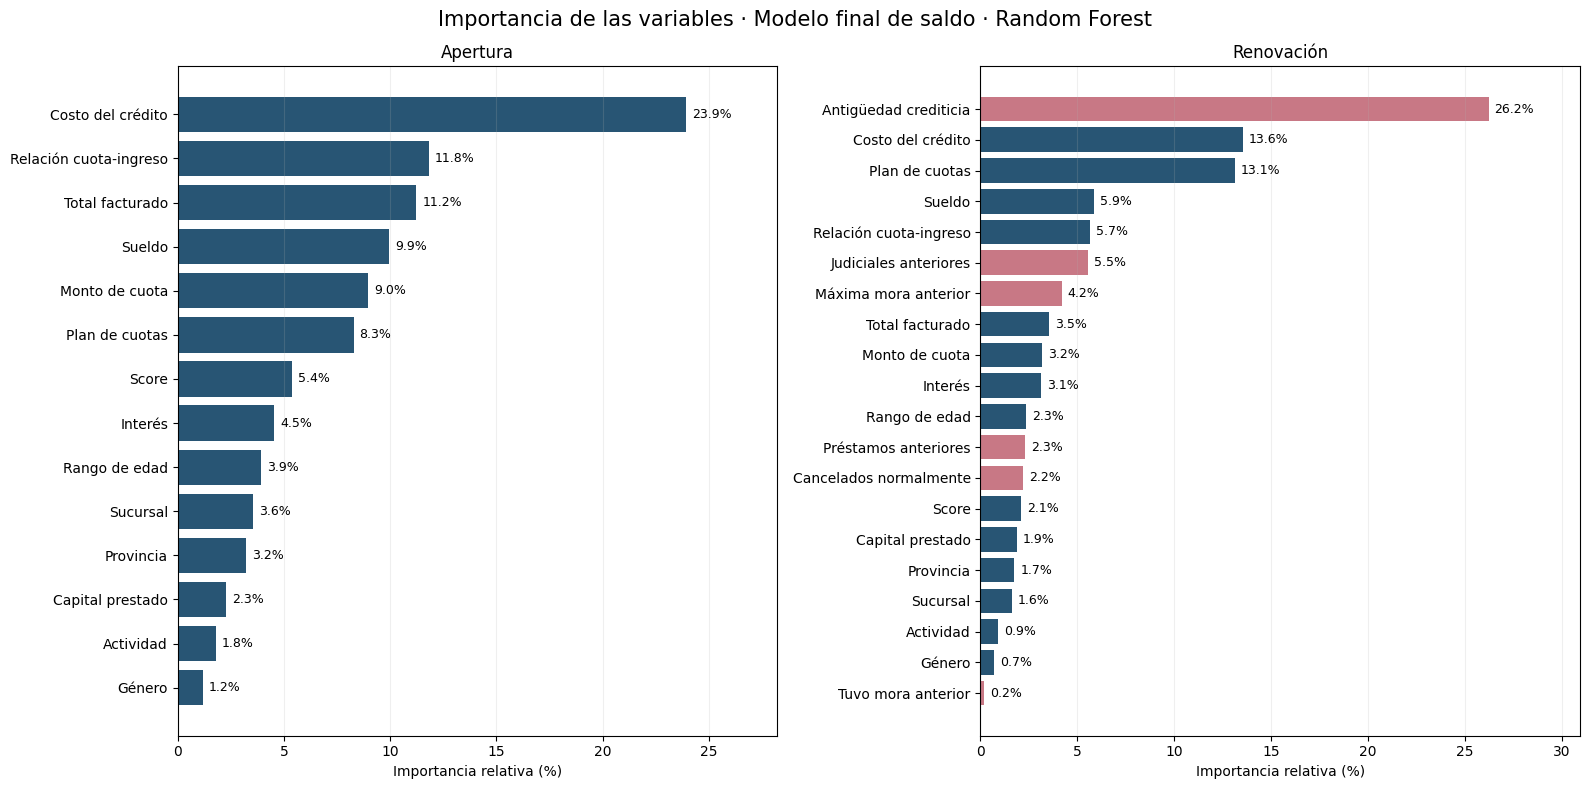

In [ ]:
# Importancias del modelo final de saldo, agrupadas por variable original.
# No se utilizan estas importancias para volver a seleccionar variables.
ETIQUETAS_SALDO = {
    'rscore': 'Score', 'capitalprestado': 'Capital prestado', 'plan': 'Plan de cuotas',
    'SUELDO': 'Sueldo', 'interes': 'Interés', 'totalfac': 'Total facturado',
    'costo_credito': 'Costo del crédito', 'monto_cuota': 'Monto de cuota',
    'actividad': 'Actividad', 'rangoedad': 'Rango de edad', 'genero': 'Género',
    'provincia': 'Provincia', 'sucursal': 'Sucursal',
    'relacion_cuota_ingreso': 'Relación cuota-ingreso',
    'antiguedad_credito': 'Antigüedad crediticia',
    'cantidad_prestamos_anteriores': 'Préstamos anteriores',
    'tuvo_mora_anterior': 'Tuvo mora anterior',
    'max_mora_prestamos_anteriores': 'Máxima mora anterior',
    'prestamos_cancelados_normal': 'Cancelados normalmente',
    'prestamos_en_judicial_anteriores': 'Judiciales anteriores'
}
HISTORICAS_SALDO = {
    'antiguedad_credito', 'cantidad_prestamos_anteriores', 'tuvo_mora_anterior',
    'max_mora_prestamos_anteriores', 'prestamos_cancelados_normal',
    'prestamos_en_judicial_anteriores'
}
tablas_importancia_saldo = []
for pob in ['Apertura', 'Renovación']:
    pipe = modelos_finales[pob]
    nombres_transformados = pipe.named_steps['pre'].get_feature_names_out()
    importancias = np.asarray(pipe.named_steps['modelo'].feature_importances_, dtype=float)
    variables_originales = CONFIG_POB[pob]['num'] + CONFIG_POB[pob]['cat']
    if len(nombres_transformados) != len(importancias):
        raise ValueError(f'{pob}: no coinciden las columnas transformadas y sus importancias.')
    filas = []
    for nombre_transformado, valor in zip(nombres_transformados, importancias):
        limpio = str(nombre_transformado).split('__', 1)[-1]
        coincidencias = [v for v in sorted(variables_originales, key=len, reverse=True)
                        if limpio == v or limpio.startswith(v + '_')]
        if not coincidencias:
            raise ValueError(f'No se pudo identificar la variable original: {nombre_transformado}')
        filas.append({'Variable': coincidencias[0], 'Importancia': valor})
    agrupada = pd.DataFrame(filas).groupby('Variable', as_index=False)['Importancia'].sum()
    agrupada = pd.DataFrame({'Variable': variables_originales}).merge(agrupada, on='Variable', how='left').fillna({'Importancia': 0.0})
    suma = agrupada['Importancia'].sum()
    agrupada['Importancia relativa (%)'] = agrupada['Importancia'] / suma * 100 if suma > 0 else 0.0
    agrupada['Población'] = pob
    agrupada['Variable mostrada'] = agrupada['Variable'].map(ETIQUETAS_SALDO).fillna(agrupada['Variable'])
    agrupada['Es historial'] = agrupada['Variable'].isin(HISTORICAS_SALDO)
    tablas_importancia_saldo.append(agrupada)
    print('IMPORTANCIA DE VARIABLES ·', pob, '·', MODELO_FINAL)
    display(agrupada[['Variable mostrada', 'Importancia relativa (%)']]
            .sort_values('Importancia relativa (%)', ascending=False)
            .style.format({'Importancia relativa (%)': '{:.2f}%'}).hide(axis='index'))
tabla_importancia_saldo = pd.concat(tablas_importancia_saldo, ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, pob in zip(axes, ['Apertura', 'Renovación']):
    datos_grafico = tabla_importancia_saldo.loc[tabla_importancia_saldo['Población'].eq(pob)].sort_values('Importancia relativa (%)')
    barras = ax.barh(datos_grafico['Variable mostrada'], datos_grafico['Importancia relativa (%)'],
                    color=['#C87885' if h else '#285574' for h in datos_grafico['Es historial']])
    limite = max(datos_grafico['Importancia relativa (%)'].max()*1.18, 1)
    for barra, valor in zip(barras, datos_grafico['Importancia relativa (%)']):
        ax.text(valor+limite*0.01, barra.get_y()+barra.get_height()/2,
                f'{valor:.1f}%', va='center', fontsize=9)
    ax.set_xlim(0, limite); ax.set_title(pob)
    ax.set_xlabel('Importancia relativa (%)'); ax.grid(axis='x', alpha=0.2)
fig.suptitle('Importancia de las variables · Modelo final de saldo · ' + str(MODELO_FINAL), fontsize=15)
fig.tight_layout()
fig.savefig(CARPETA / '04_IMPORTANCIA_VARIABLES_SALDO.png', dpi=220, bbox_inches='tight')
plt.show()


## 13. Integración con el modelo de clasificación RGJ

A partir de esta etapa, el modelo de saldo trabaja únicamente con los préstamos de 2026 que fueron clasificados con alerta de riesgo de derivación a Gestión Judicial.

El flujo operativo es:

**Cartera activa al 01/04/2026 → clasificación del riesgo RGJ → préstamos con alerta → estimación del saldo potencial al pase**

El notebook lee el archivo generado por `03_CLASIFICACION_RGJ_CON_XGBOOST_TESIS_UGR.ipynb`:

`RESULTADOS_VALIDACION_2026_AL_01_09.xlsx`

y utiliza la hoja:

`Prestamos_2026`

Luego conserva exclusivamente las operaciones con `pred_judicial = 1`. El saldo se estima para esas mismas operaciones, sin utilizar el desenlace ni el saldo real como variables predictoras.


In [ ]:
# ============================================================
# SALIDA DEL MODELO DE CLASIFICACIÓN RGJ
# ============================================================

RUTA_MODELO_CLASIFICACION = (
    CARPETA /
    'RESULTADOS_VALIDACION_2026_AL_01_09.xlsx'
)

if not RUTA_MODELO_CLASIFICACION.exists():
    raise FileNotFoundError(
        f"No se encontró la salida del modelo de clasificación:\n"
        f"{RUTA_MODELO_CLASIFICACION}\n\n"
        "Ejecutá primero el notebook "
        "'03_CLASIFICACION_RGJ_CON_XGBOOST_TESIS_UGR.ipynb'."
    )

# La hoja Prestamos_2026 contiene el detalle completo de las
# operaciones clasificadas y su comparación posterior.
predicciones_clasificacion = pd.read_excel(
    RUTA_MODELO_CLASIFICACION,
    sheet_name='Prestamos_2026'
)

predicciones_clasificacion.columns = [
    str(c).strip()
    for c in predicciones_clasificacion.columns
]

requeridas_clasificacion = [
    'poblacion_modelo',
    'prob_judicial',
    'pred_judicial'
]

faltantes_clasificacion = [
    columna
    for columna in requeridas_clasificacion
    if columna not in predicciones_clasificacion.columns
]

if faltantes_clasificacion:
    raise KeyError(
        "La salida del modelo de clasificación no contiene "
        f"las siguientes columnas: {faltantes_clasificacion}"
    )

predicciones_clasificacion['pred_judicial'] = pd.to_numeric(
    predicciones_clasificacion['pred_judicial'],
    errors='coerce'
)

if predicciones_clasificacion['pred_judicial'].isna().any():
    raise ValueError(
        "La columna 'pred_judicial' contiene valores no válidos."
    )

# Se seleccionan los préstamos clasificados con riesgo de
# derivación a Gestión Judicial.
alertas_clasificacion = (
    predicciones_clasificacion[
        predicciones_clasificacion['pred_judicial'].eq(1)
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    'Operaciones evaluadas por el modelo de clasificación:',
    f'{len(predicciones_clasificacion):,}'.replace(',', '.')
)

print(
    'Operaciones clasificadas con alerta judicial:',
    f'{len(alertas_clasificacion):,}'.replace(',', '.')
)

if 'id_cliente' in alertas_clasificacion.columns:
    print(
        'Clientes únicos con alerta judicial:',
        f"{alertas_clasificacion['id_cliente'].nunique():,}".replace(',', '.')
    )

print('\nAlertas judiciales por población:')

display(
    alertas_clasificacion
    .groupby(
        'poblacion_modelo',
        dropna=False
    )
    .size()
    .rename('Operaciones')
    .reset_index()
)

Operaciones evaluadas por el modelo de clasificación: 3.032
Operaciones clasificadas con alerta judicial: 1.929
Clientes únicos con alerta judicial: 1.924

Alertas judiciales por población:


,poblacion_modelo,Operaciones
0,Apertura,1104
1,Renovación,825


## 14. Estimación del saldo para los préstamos con alerta judicial

Se controla que cada operación identificada con alerta por el modelo de clasificación reciba exactamente una estimación de saldo.

Si la cantidad de alertas no coincide con la cantidad de saldos estimados, el código se detiene para evitar pérdidas o duplicaciones de registros.


In [ ]:

# Recalcular relación cuota/ingreso sólo si hace falta
if 'relacion_cuota_ingreso' not in alertas_clasificacion.columns:
    alertas_clasificacion['relacion_cuota_ingreso'] = np.where(
        pd.to_numeric(
            alertas_clasificacion['SUELDO'],
            errors='coerce'
        ) > 0,
        pd.to_numeric(
            alertas_clasificacion['monto_cuota'],
            errors='coerce'
        ) /
        pd.to_numeric(
            alertas_clasificacion['SUELDO'],
            errors='coerce'
        ) * 100,
        np.nan
    )

partes_saldo = []

for pob in ['Apertura', 'Renovación']:

    sub = alertas_clasificacion[
        alertas_clasificacion['poblacion_modelo'].eq(pob)
    ].copy()

    if sub.empty:
        print(pob, ': sin operaciones marcadas')
        continue

    variables = (
        CONFIG_POB[pob]['num'] +
        CONFIG_POB[pob]['cat']
    )

    faltantes = [
        c for c in variables
        if c not in sub.columns
    ]

    if faltantes:
        raise KeyError(
            f'{pob}: faltan variables provenientes del modelo de clasificación: {faltantes}'
        )

    ratio_pred = np.clip(
        modelos_finales[pob].predict(
            sub[variables]
        ),
        0,
        1
    )

    sub['ratio_saldo_estimado_gj'] = ratio_pred

    sub['saldo_estimado_gj'] = (
        ratio_pred *
        pd.to_numeric(
            sub['totalfac'],
            errors='coerce'
        )
    )

    sub['modelo_saldo'] = MODELO_FINAL

    partes_saldo.append(sub)

resultado_final = pd.concat(
    partes_saldo,
    ignore_index=True
)

# ------------------------------------------------------------
# CONTROL CRÍTICO DE ALINEACIÓN
# ------------------------------------------------------------
n_alertas_clasificacion = len(alertas_clasificacion)
n_saldos_estimados = len(resultado_final)

print('Operaciones con alerta del modelo de clasificación:', f'{n_alertas_clasificacion:,}')
print('Operaciones con saldo estimado:', f'{n_saldos_estimados:,}')

assert n_alertas_clasificacion == n_saldos_estimados, (
    'ERROR: la cantidad de alertas no coincide con la cantidad de saldos estimados.'
)

print('\n✅ CONTROL CORRECTO')
print(
    'Cada operación con alerta tiene exactamente '
    'una estimación de saldo.'
)


Operaciones con alerta del modelo de clasificación: 1,929
Operaciones con saldo estimado: 1,929

✅ CONTROL CORRECTO
Cada operación con alerta tiene exactamente una estimación de saldo.


## 15. Resultado conjunto: alertas y saldo potencial estimado

In [ ]:

# Columnas para conteo de clientes y operaciones
COL_OPERACION = None

for posible in [
    'operacion',
    'factura',
    'nrofactura'
]:
    if posible in resultado_final.columns:
        COL_OPERACION = posible
        break

if COL_OPERACION is None:
    resultado_final['_operacion_aux'] = np.arange(
        len(resultado_final)
    )
    COL_OPERACION = '_operacion_aux'

def resumen_grupo(g):
    return pd.Series({
        'Operaciones_estimadas_GJ':
            g[COL_OPERACION].nunique(),
        'Clientes_unicos_estimados_GJ':
            g['id_cliente'].nunique()
            if 'id_cliente' in g.columns
            else np.nan,
        'Probabilidad_media_GJ':
            pd.to_numeric(
                g['prob_judicial'],
                errors='coerce'
            ).mean(),
        'Total_facturado_$':
            pd.to_numeric(
                g['totalfac'],
                errors='coerce'
            ).sum(),
        'Ratio_saldo_estimado_medio':
            g['ratio_saldo_estimado_gj'].mean(),
        'Saldo_estimado_al_pase_GJ_$':
            g['saldo_estimado_gj'].sum()
    })

resumen_pipeline = (
    resultado_final
    .groupby(
        'poblacion_modelo',
        dropna=False
    )
    .apply(resumen_grupo)
    .reset_index()
)

total = pd.DataFrame([{
    'poblacion_modelo': 'TOTAL',
    'Operaciones_estimadas_GJ':
        resultado_final[COL_OPERACION].nunique(),
    'Clientes_unicos_estimados_GJ':
        resultado_final['id_cliente'].nunique()
        if 'id_cliente' in resultado_final.columns
        else np.nan,
    'Probabilidad_media_GJ':
        pd.to_numeric(
            resultado_final['prob_judicial'],
            errors='coerce'
        ).mean(),
    'Total_facturado_$':
        pd.to_numeric(
            resultado_final['totalfac'],
            errors='coerce'
        ).sum(),
    'Ratio_saldo_estimado_medio':
        resultado_final[
            'ratio_saldo_estimado_gj'
        ].mean(),
    'Saldo_estimado_al_pase_GJ_$':
        resultado_final[
            'saldo_estimado_gj'
        ].sum()
}])

resumen_pipeline = pd.concat(
    [
        resumen_pipeline,
        total
    ],
    ignore_index=True
)

display(
    resumen_pipeline.style.format({
        'Operaciones_estimadas_GJ': '{:,.0f}',
        'Clientes_unicos_estimados_GJ': '{:,.0f}',
        'Probabilidad_media_GJ': '{:.2%}',
        'Total_facturado_$': '${:,.0f}',
        'Ratio_saldo_estimado_medio': '{:.2%}',
        'Saldo_estimado_al_pase_GJ_$': '${:,.0f}'
    }).hide(axis='index')
)


poblacion_modelo,Operaciones_estimadas_GJ,Clientes_unicos_estimados_GJ,Probabilidad_media_GJ,Total_facturado_$,Ratio_saldo_estimado_medio,Saldo_estimado_al_pase_GJ_$
Apertura,"1,104","1,104",73.45%,"$4,794,562,319",83.44%,"$4,137,026,162"
Renovación,825,820,77.07%,"$3,694,737,416",97.81%,"$3,608,774,920"
TOTAL,"1,929","1,924",75.00%,"$8,489,299,734",89.58%,"$7,745,801,082"


## 16. Validación con los saldos reales observados

Para los préstamos alertados que efectivamente fueron derivados a Gestión Judicial hasta el 01/09/2026, se compara el saldo estimado con el saldo real conservado al momento del pase.

Esta validación permite medir el error económico del modelo sobre una cohorte posterior. Los resultados reales se utilizan únicamente para evaluar la estimación y no modifican las predicciones generadas.


In [ ]:
# ============================================================
# VALIDACIÓN CON EL SALDO REAL OBSERVADO AL PASE JUDICIAL
# ============================================================

# Columnas generadas por el notebook de clasificación RGJ.
COL_FECHA_REAL = 'fecha_judicial_real'
COL_SALDO_REAL = 'saldo_real_pase'

columnas_requeridas_control = [
    COL_FECHA_REAL,
    COL_SALDO_REAL,
    'saldo_estimado_gj'
]

faltantes_control = [
    columna
    for columna in columnas_requeridas_control
    if columna not in resultado_final.columns
]

if faltantes_control:
    tabla_control_real = pd.DataFrame()

    print(
        'No se pudo realizar la validación del saldo porque '
        'faltan las siguientes columnas:'
    )
    print(faltantes_control)

else:
    resultado_final[COL_FECHA_REAL] = pd.to_datetime(
        resultado_final[COL_FECHA_REAL],
        errors='coerce',
        dayfirst=True
    )

    resultado_final[COL_SALDO_REAL] = pd.to_numeric(
        resultado_final[COL_SALDO_REAL],
        errors='coerce'
    )

    resultado_final['saldo_estimado_gj'] = pd.to_numeric(
        resultado_final['saldo_estimado_gj'],
        errors='coerce'
    )

    # Se consideran únicamente los préstamos que:
    # 1. fueron clasificados con alerta judicial;
    # 2. llegaron efectivamente a Gestión Judicial hasta la fecha de corte;
    # 3. tienen saldo real y saldo estimado disponibles.
    mascara_control_real = (
        resultado_final[COL_FECHA_REAL].notna()
        & resultado_final[COL_FECHA_REAL].le(FECHA_CORTE)
        & resultado_final[COL_SALDO_REAL].notna()
        & resultado_final['saldo_estimado_gj'].notna()
    )

    if 'pred_judicial' in resultado_final.columns:
        mascara_control_real &= (
            pd.to_numeric(
                resultado_final['pred_judicial'],
                errors='coerce'
            ).eq(1)
        )

    if 'judicial_real' in resultado_final.columns:
        mascara_control_real &= (
            pd.to_numeric(
                resultado_final['judicial_real'],
                errors='coerce'
            ).eq(1)
        )

    val_real = (
        resultado_final.loc[mascara_control_real]
        .copy()
        .reset_index(drop=True)
    )

    if not val_real.empty:
        val_real['saldo_real_gj'] = val_real[COL_SALDO_REAL]

        met_real = metricas_saldo(
            val_real['saldo_real_gj'],
            val_real['saldo_estimado_gj']
        )

        tabla_control_real = pd.DataFrame([{
            'Casos con alerta que llegaron a Gestión Judicial':
                len(val_real),
            **met_real
        }])

        print(
            'Casos con alerta que llegaron a Gestión Judicial '
            'y tienen saldo real observable:',
            f'{len(val_real):,}'.replace(',', '.')
        )

        display(
            tabla_control_real.style.format({
                'MAE_$': '${:,.0f}',
                'RMSE_$': '${:,.0f}',
                'R2_$': '{:.4f}',
                'Sesgo_$': '${:,.0f}',
                'Mediana_abs_error_$': '${:,.0f}',
                'Saldo_real_$': '${:,.0f}',
                'Saldo_estimado_$': '${:,.0f}',
                'Diferencia_$': '${:,.0f}',
                'Error_agregado_%': '{:.3f}%'
            }).hide(axis='index')
        )

    else:
        tabla_control_real = pd.DataFrame()

        print(
            'No hay préstamos con alerta que hayan llegado a '
            'Gestión Judicial y tengan saldo real observable '
            'hasta la fecha de corte.'
        )

Casos con alerta que llegaron a Gestión Judicial y tienen saldo real observable: 282


Casos con alerta que llegaron a Gestión Judicial,Casos,MAE_$,RMSE_$,R2_$,Sesgo_$,Mediana_abs_error_$,Saldo_real_$,Saldo_estimado_$,Diferencia_$,Error_agregado_%
282,282,"$480,071","$630,915",0.9508,"$-471,796","$387,327","$1,338,509,249","$1,205,462,731","$-133,046,518",-9.940%


### 16.1. Saldo real frente al estimado en la cartera de 2026

El gráfico incluye únicamente las operaciones alertadas que llegaron a Gestión Judicial y cuentan con saldo real observable. No incluye todas las operaciones con alerta ni se utiliza para seleccionar el algoritmo.


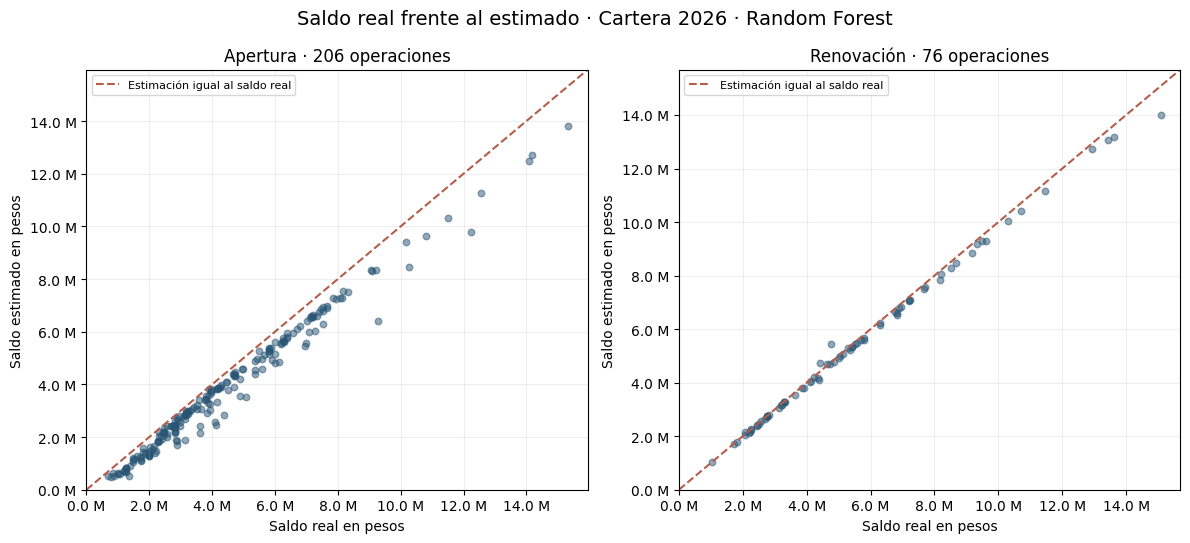

In [ ]:
# Se utilizan solamente los casos alertados con pase y saldo real observables.
if 'val_real' in globals() and not val_real.empty:
    graficar_real_estimado_saldo(
        val_real, 'saldo_real_gj', 'saldo_estimado_gj', 'poblacion_modelo',
        'Saldo real frente al estimado · Cartera 2026 · ' + str(MODELO_FINAL),
        CARPETA / '04_REAL_VS_ESTIMADO_2026.png'
    )
else:
    print('No hay casos con saldo real observable para generar el gráfico de 2026.')


## 17. Exportación de las estimaciones y resultados

Se exportan la comparación de algoritmos, las métricas del modelo seleccionado, el detalle de los préstamos alertados con su saldo estimado y la validación contra los saldos reales disponibles.


In [ ]:
# ============================================================
# EXPORTACIÓN DEL RESULTADO INTEGRADO:
# CLASIFICACIÓN RGJ Y ESTIMACIÓN DEL SALDO
# ============================================================

RUTA_SALIDA_PIPELINE = (
    CARPETA /
    'RESULTADOS_CLASIFICACION_Y_ESTIMACION_SALDO_2026.xlsx'
)

# Se colocan primero las variables más importantes para
# interpretar la clasificación y la estimación del saldo.
columnas_prioritarias = [
    columna
    for columna in [
        'id_cliente',
        'operacion',
        'factura',
        'nrofactura',
        'añofac',
        'mesfac',
        'tipocredito',
        'poblacion_modelo',
        'rscore',
        'grupo_score',
        'sucursal',
        'provincia',
        'capitalprestado',
        'totalfac',

        # Resultado del modelo de clasificación
        'prob_judicial',
        'prob_judicial_pct',
        'umbral_modelo',
        'pred_judicial',
        'prediccion_modelo',

        # Resultado del modelo de saldo
        'ratio_saldo_estimado_gj',
        'saldo_estimado_gj',
        'modelo_saldo',

        # Resultado real observado
        'judicial_real',
        'fecha_judicial_real',
        'saldo_real_pase',
        'situacion_al_01_09',
        'resultado_validacion'
    ]
    if columna in resultado_final.columns
]

otras_columnas = [
    columna
    for columna in resultado_final.columns
    if columna not in columnas_prioritarias
]

detalle_exportar = resultado_final[
    columnas_prioritarias + otras_columnas
].copy()

with pd.ExcelWriter(
    RUTA_SALIDA_PIPELINE,
    engine='openpyxl'
) as writer:

    resumen_pipeline.to_excel(
        writer,
        sheet_name='Resumen_Integrado',
        index=False
    )

    detalle_exportar.to_excel(
        writer,
        sheet_name='Alertas_y_Saldos',
        index=False
    )

    tabla_mejor_cv.to_excel(
        writer,
        sheet_name='Comparacion_Modelos_Saldo',
        index=False
    )

    tabla_test.to_excel(
        writer,
        sheet_name='Evaluacion_Modelo_Saldo',
        index=False
    )

    tabla_importancia_saldo.to_excel(
        writer, sheet_name='Importancia_Variables', index=False
    )

    if not tabla_control_real.empty:
        tabla_control_real.to_excel(
            writer,
            sheet_name='Validacion_Saldo_Real_2026',
            index=False
        )

print('Resultados integrados guardados correctamente en:')
print(RUTA_SALIDA_PIPELINE)

print('\nORDEN DE EJECUCIÓN:')

print(
    '1. Ejecutar el notebook de clasificación '
    '03__Clasificacion_RGJ_CON_XGBOOST.ipynb'
)

print(
    '2. Ejecutar el notebook de estimación del saldo.'
)

print(
    '3. El modelo de saldo toma las operaciones clasificadas '
    'con alerta de Gestión Judicial y estima el posible saldo '
    'al momento de la derivación.'
)

print(
    '4. Cuando existe un saldo real observado, la estimación '
    'se compara con el saldo registrado al pase judicial.'
)

Resultados integrados guardados correctamente en:
/content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/RESULTADOS_CLASIFICACION_Y_ESTIMACION_SALDO_2026.xlsx

ORDEN DE EJECUCIÓN:
1. Ejecutar el notebook de clasificación 03__Clasificacion_RGJ_CON_XGBOOST.ipynb
2. Ejecutar el notebook de estimación del saldo.
3. El modelo de saldo toma las operaciones clasificadas con alerta de Gestión Judicial y estima el posible saldo al momento de la derivación.
4. Cuando existe un saldo real observado, la estimación se compara con el saldo registrado al pase judicial.


**Conclusion:**

La comparación entre Random Forest Regressor y XGBoost Regressor permitió seleccionar Random Forest por su menor MAE promedio de validación cruzada entre Apertura y Renovación. El modelo se aplicó a las 1.929 operaciones de 2026 previamente clasificadas con alerta. En las 282 que llegaron a Gestión Judicial y contaban con saldo real, el saldo total estimado quedó un 9,94% por debajo del observado. Esta comparación permitió evaluar las estimaciones con datos reales de un período posterior al utilizado para desarrollar el modelo.